# Crossed multi-agent routes in Bench-MR `testing_warehouse2`

This notebook contains two four-agent scenarios in the `warehouse2` central bottleneck. `close_crossing` is solvable close-range traffic. `symmetric_head_on_deadlock` adds exact reverse routes so two pairs meet head-on in a deadlock-prone bottleneck; depending on the sampled controls, they may also pass. Select one with `SCENARIO`; both expose editable starts and goals like `bench_mr.ipynb`. The second agent retains the published `testing_warehouse2` poses.

Before running, rebuild the native controller with `cmake --build build/release --target mppi_all -j2`, then restart the Jupyter kernel and run all cells. Python keeps an already-imported `mppi_ca_cpp` binary loaded even if its source or on-disk build changes.

The default `close_crossing` enables the new smooth-tracking settings. The head-on stress case retains the original controller profile so its behavior can be compared; the GIF below captures a run that stalled.

Successful close crossing:

![Warehouse2 crossed-route animation](rrt_connect_warehouse2_multiagent.gif)

Recorded head-on deadlock run:

![Warehouse2 deadlock animation](rrt_connect_warehouse2_deadlock.gif)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner, RRTConnectResult
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())

## Custom starts and goals

Set `SCENARIO` to `close_crossing` or `symmetric_head_on_deadlock`. You can then edit the selected `CUSTOM_STARTS` and `CUSTOM_GOALS`; every row is `[x, y, theta]`. The second row deliberately matches the published `testing_warehouse2` task exactly.

In [2]:
CUSTOM_WORLD = 'warehouse2'
REFERENCE_TASK_ID = 'testing_warehouse2'
SCENARIO = 'close_crossing'  # or 'symmetric_head_on_deadlock'

SCENARIOS = {
    'close_crossing': {
        'agent_names': [
            'bottom-left to top-right', REFERENCE_TASK_ID,
            'mid-left lower to mid-right upper',
            'mid-left upper to mid-right lower',
        ],
        'starts': [
            [7.5, -70.0,  0.50], [7.5, -10.0, -1.58],
            [7.5, -50.0,  0.00], [7.5, -30.0,  0.00],
        ],
        'goals': [
            [116.0, -10.0,  0.50], [116.0, -70.0, -1.58],
            [116.0, -30.0,  0.00], [116.0, -50.0,  0.00],
        ],
        'expected_success': True,
        'gif': 'rrt_connect_warehouse2_multiagent.gif',
        'extra_obstacles': [],
    },
    'symmetric_head_on_deadlock': {
        'agent_names': [
            'bottom-left to top-right', REFERENCE_TASK_ID,
            'top-right to bottom-left', 'bottom-right to top-left',
        ],
        'starts': [
            [7.5, -70.0,  0.50], [7.5, -10.0, -1.58],
            [116.0, -10.0, -2.64], [116.0, -70.0, 2.64],
        ],
        'goals': [
            [116.0, -10.0,  0.50], [116.0, -70.0, -1.58],
            [7.5, -70.0, -2.64], [7.5, -10.0, 2.64],
        ],
        'expected_success': None,  # head-on traffic may stall or clear the gate
        'gif': 'rrt_connect_warehouse2_deadlock.gif',
        # Two short extensions turn the existing central gap into a
        # one-robot-wide gate. Opposing agents cannot pass side by side.
        'extra_obstacles': [
            [[76.9, -38.9], [81.1, -38.9], [81.1, -34.2], [76.9, -34.2]],
            [[76.9, -43.8], [81.1, -43.8], [81.1, -40.1], [76.9, -40.1]],
        ],
    },
}

if SCENARIO not in SCENARIOS:
    raise ValueError(f'Unknown scenario {SCENARIO!r}; choose one of {list(SCENARIOS)}')
scenario_config = SCENARIOS[SCENARIO]
AGENT_NAMES = scenario_config['agent_names']
CUSTOM_STARTS = np.asarray(scenario_config['starts'], dtype=float)
CUSTOM_GOALS = np.asarray(scenario_config['goals'], dtype=float)
EXPECTED_SUCCESS = scenario_config['expected_success']

SEED = 42
ROBOT_RADIUS = 0.3
PLANNER_CLEARANCE = 0.15

if CUSTOM_WORLD not in suite['worlds']:
    raise ValueError(f'Unknown Bench-MR world: {CUSTOM_WORLD}')
if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.ndim != 2 or CUSTOM_STARTS.shape[1] != 3:
    raise ValueError('CUSTOM_STARTS and CUSTOM_GOALS must be matching N x 3 arrays')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Custom poses must be finite')
if len(AGENT_NAMES) != len(CUSTOM_STARTS):
    raise ValueError('Provide one AGENT_NAMES entry per custom route')

reference_task = next(task for task in suite['tasks'] if task['id'] == REFERENCE_TASK_ID)
if not np.allclose(CUSTOM_STARTS[1], reference_task['start']) or not np.allclose(CUSTOM_GOALS[1], reference_task['goal']):
    raise ValueError('The second custom route must retain the published testing_warehouse2 poses')

world = suite['worlds'][CUSTOM_WORLD]
scenario_obstacles = world['obstacles'] + scenario_config['extra_obstacles']
tasks = [
    {'id': name, 'world': CUSTOM_WORLD, 'group': 'custom',
     'start': start.tolist(), 'goal': goal.tolist()}
    for name, start, goal in zip(AGENT_NAMES, CUSTOM_STARTS, CUSTOM_GOALS)
]
print(f'Scenario: {SCENARIO}; expected success: {EXPECTED_SUCCESS if EXPECTED_SUCCESS is not None else "variable"}')
print(f'World: {CUSTOM_WORLD}; agents: {AGENT_NAMES}; obstacles: {len(scenario_obstacles)}')

Scenario: close_crossing; expected success: True
World: warehouse2; agents: ['bottom-left to top-right', 'testing_warehouse2', 'mid-left lower to mid-right upper', 'mid-left upper to mid-right lower']; obstacles: 80


## RRT-Connect and shortcut smoothing

The planner inflates every polygon by the robot radius plus clearance. Dotted paths below are raw RRT-Connect results; dashed paths are the collision-checked, smoothed anchors passed to MPPI.

In [3]:
planning_results = []
planned_agent_count = 2 if SCENARIO == 'symmetric_head_on_deadlock' else len(tasks)
for agent_id, task in enumerate(tasks[:planned_agent_count]):
    planner = RRTConnectPlanner(
        obstacles=scenario_obstacles, bounds=world['bounds'],
        robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
        step_size=1.5, max_iterations=100_000, goal_sample_rate=0.05,
        smoothing_iterations=800, seed=SEED + agent_id,
    )
    result = planner.plan(task['start'][:2], task['goal'][:2])
    planning_results.append(result)
if SCENARIO == 'symmetric_head_on_deadlock':
    for forward_result in planning_results[:2]:
        planning_results.append(RRTConnectResult(
            raw_path=list(reversed(forward_result.raw_path)),
            path=list(reversed(forward_result.path)),
            iterations=0,
        ))

for task, result in zip(tasks, planning_results):
    raw_length = sum(np.linalg.norm(np.subtract(b, a)) for a, b in zip(result.raw_path, result.raw_path[1:]))
    smooth_length = sum(np.linalg.norm(np.subtract(b, a)) for a, b in zip(result.path, result.path[1:]))
    print(
        f"{task['id']}: iterations={result.iterations}, "
        f"raw={len(result.raw_path)} vertices/{raw_length:.2f} units, "
        f"smoothed={len(result.path)} vertices/{smooth_length:.2f} units"
    )
anchor_paths = [result.path for result in planning_results]
if SCENARIO == 'symmetric_head_on_deadlock':
    assert np.allclose(anchor_paths[2], anchor_paths[0][::-1])
    assert np.allclose(anchor_paths[3], anchor_paths[1][::-1])

bottom-left to top-right: iterations=350, raw=105 vertices/154.63 units, smoothed=7 vertices/142.31 units
testing_warehouse2: iterations=132, raw=101 vertices/148.86 units, smoothed=10 vertices/137.43 units
mid-left lower to mid-right upper: iterations=66, raw=84 vertices/123.53 units, smoothed=6 vertices/118.41 units
mid-left upper to mid-right lower: iterations=180, raw=87 vertices/127.51 units, smoothed=7 vertices/121.46 units


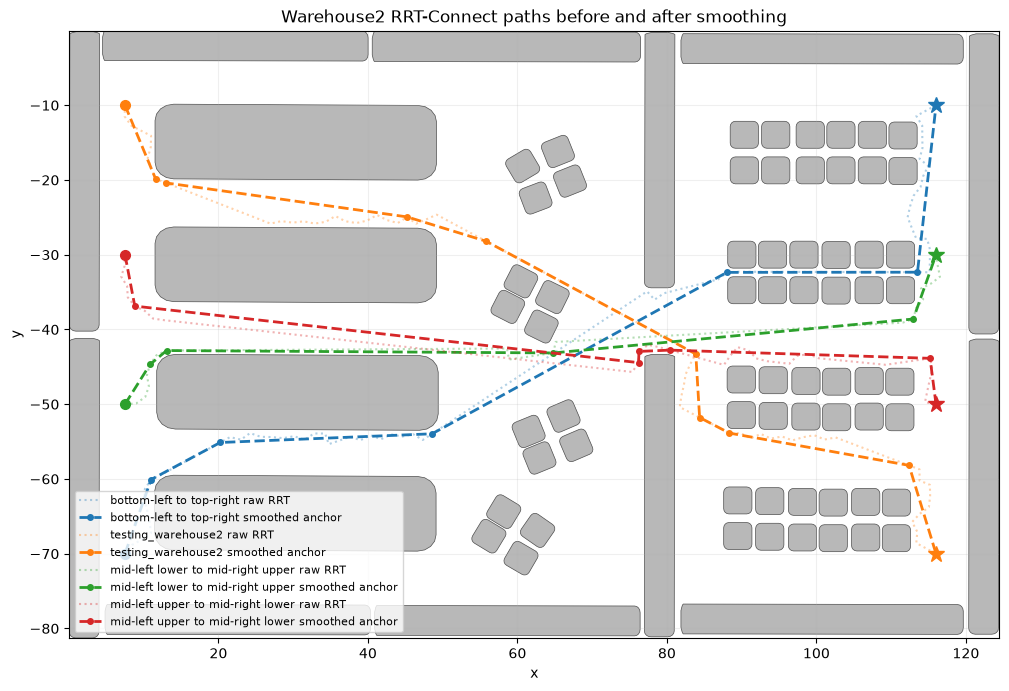

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(tasks)))

def draw_world(ax):
    for polygon in scenario_obstacles:
        ax.add_patch(PolygonPatch(polygon, closed=True, facecolor='0.72',
                                  edgecolor='0.3', linewidth=0.5))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (task, result) in enumerate(zip(tasks, planning_results)):
    raw = np.asarray(result.raw_path)
    anchor = np.asarray(result.path)
    color = colors[agent_id]
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.35, label=f"{task['id']} raw RRT")
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=color, linewidth=2,
            markersize=4, label=f"{task['id']} smoothed anchor")
    ax.plot(*task['start'][:2], 'o', color=color, markersize=7)
    ax.plot(*task['goal'][:2], '*', color=color, markersize=12)
ax.set_title('Warehouse2 RRT-Connect paths before and after smoothing')
ax.legend(fontsize=8, loc='best')
plt.show()

## Concurrent ORCA-MPPI execution

This large map uses a faster differential-drive profile and a shorter sampling horizon than the small parking example. The default `close_crossing` scenario enables heading-to-anchor and control-change costs to discourage zigzag tracking, plus an angular acceleration limit on planned turns. Static swept-segment collision checks, boundary walls, and ORCA neighbor constraints remain enabled. The post-run report checks every agent pair, reports physical clearance, and identifies unfinished agents that stopped moving near the end of the run. The `symmetric_head_on_deadlock` scenario retains the original controller profile and may stall or clear the bottleneck; the recorded GIF shows a stalled run. An emergency stop when no safe rollout exists can override the turn-change limit.

In [5]:
AGENTS_NUM = len(tasks)
SMOOTH_TRACKING = SCENARIO == 'close_crossing'
DT = 0.1
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 2))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 2))]

default_agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: 8.0, DIFF_DRIVE_V_MIN: -0.01,
    DIFF_DRIVE_W_MAX: 5.0, DIFF_DRIVE_W_MIN: -5.0,
    DIFF_DRIVE_W_ACCEL_MAX: 10.0 if SMOOTH_TRACKING else 0.0,
}
agents_params = [default_agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.DiffDriveDyn() for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 200, SAMPLE_TIME_STEPS: 15, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    CONTROL_COV: np.diag([25.0, 16.0]),
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: False,
    K_ALPHA: -2.96, RAD_EPS: 0.05, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 2000.0,
    ANCHOR_HEADING_WEIGHT: 500.0 if SMOOTH_TRACKING else 0.0,
    CONTROL_SMOOTHNESS_WEIGHT: 20.0 if SMOOTH_TRACKING else 0.0,
}
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 0.7, MAX_EXP_STEPS: 350}

expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = scenario_obstacles + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
goal_errors = np.linalg.norm(states[-1, :, :2] - goal_states[:, :2], axis=1)
pairwise_minima = []
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        distances = np.linalg.norm(states[:, first, :2] - states[:, second, :2], axis=1)
        closest_step = int(np.argmin(distances))
        pairwise_minima.append((float(distances[closest_step]), first, second, closest_step))
closest_distance, closest_first, closest_second, closest_step = min(pairwise_minima)
surface_clearance = closest_distance - 2.0 * ROBOT_RADIUS
lookback = min(30, len(states) - 1)
recent_motion = np.linalg.norm(states[-1, :, :2] - states[-1 - lookback, :, :2], axis=1)
stalled = (goal_errors > exp_params[XY_GOAL_TOLERANCE]) & (recent_motion < 0.5)
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
if EXPECTED_SUCCESS is not None:
    print(f'outcome matches scenario expectation: {bool(success) == EXPECTED_SUCCESS}')
print(
    f'closest pair: {tasks[closest_first]["id"]} / {tasks[closest_second]["id"]}; '
    f'center distance={closest_distance:.3f}, surface clearance={surface_clearance:.3f}, '
    f'step={closest_step}'
)
for task, error in zip(tasks, goal_errors):
    print(f"{task['id']}: final XY error={error:.3f}")
stalled_names = [tasks[index]['id'] for index in np.flatnonzero(stalled)]
print(f'stalled unfinished agents: {stalled_names or "none"}')

success=True, collisions=0.0, steps=260, wall time=100.64s
outcome matches scenario expectation: True
closest pair: testing_warehouse2 / mid-left upper to mid-right lower; center distance=1.566, surface clearance=0.966, step=136
bottom-left to top-right: final XY error=0.474
testing_warehouse2: final XY error=0.106
mid-left lower to mid-right upper: final XY error=0.143
mid-left upper to mid-right lower: final XY error=0.427
stalled unfinished agents: none


## Executed paths and animated GIF

Dotted lines are raw RRT paths, dashed lines are smoothed anchors, and solid lines are executed trajectories. The animation keeps the smoothed anchors visible and samples at most 180 simulation frames to keep the GIF manageable.

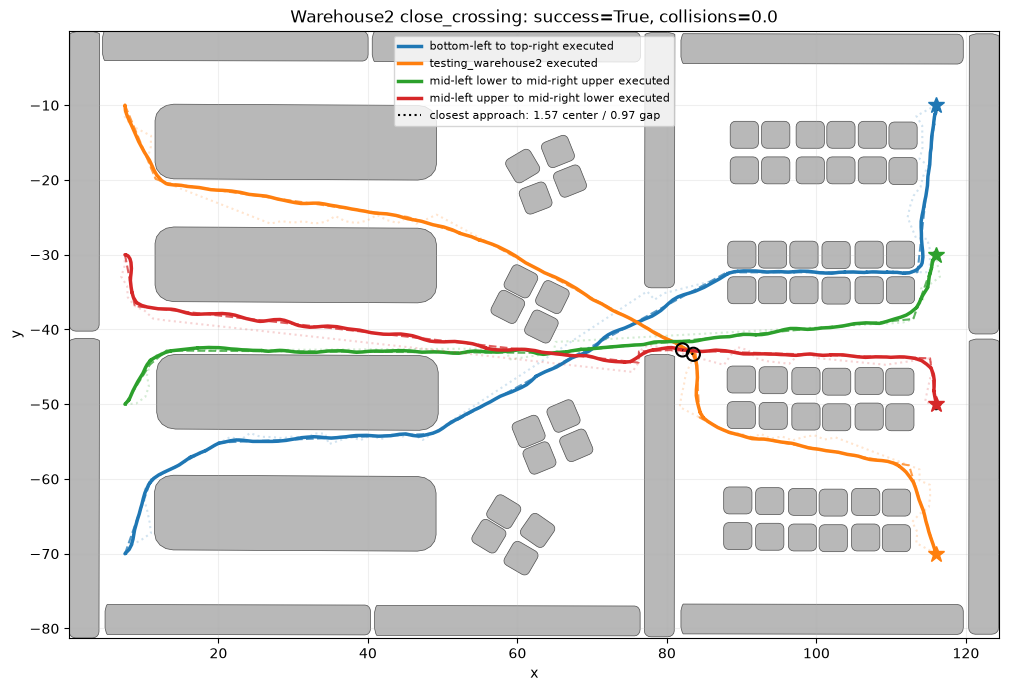

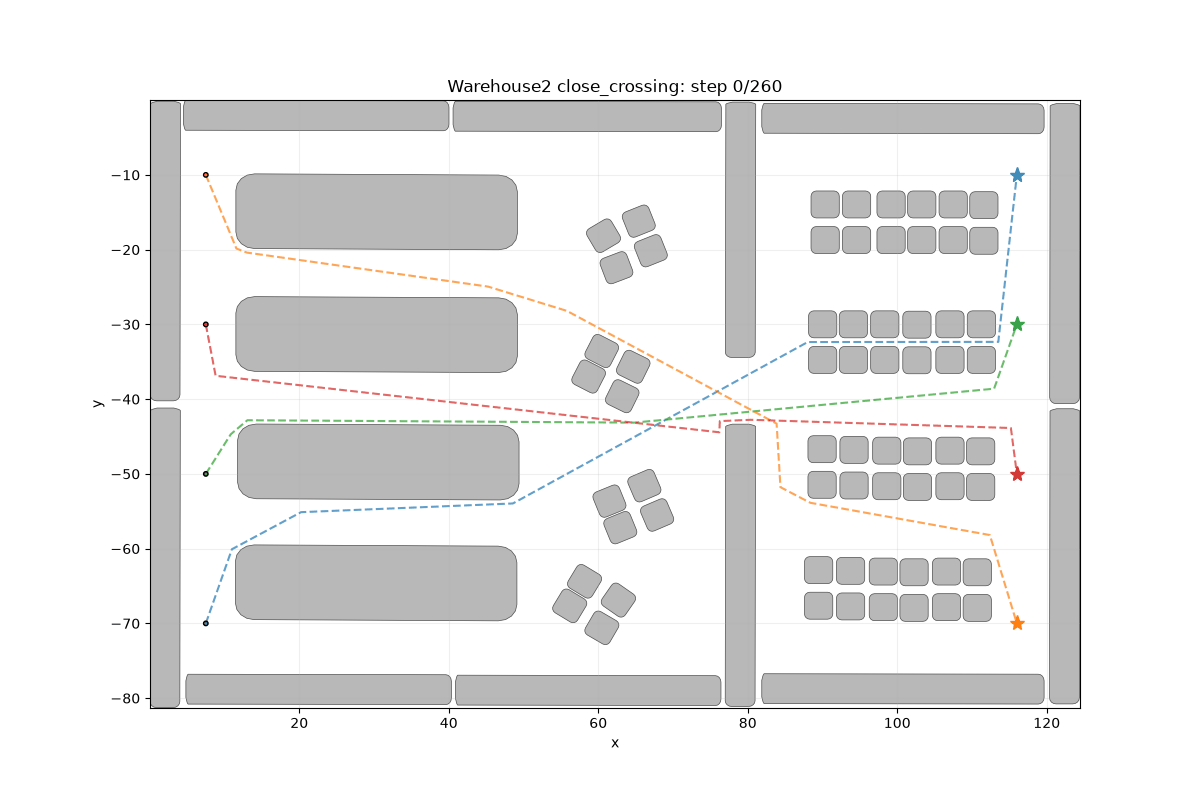

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (task, result) in enumerate(zip(tasks, planning_results)):
    color = colors[agent_id]
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.2)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.75, linewidth=1.5)
    ax.plot(states[:, agent_id, 0], states[:, agent_id, 1], color=color,
            linewidth=2.5, label=f"{task['id']} executed")
    ax.add_patch(Circle(states[-1, agent_id, :2], ROBOT_RADIUS,
                        facecolor=color, edgecolor='black', alpha=0.8))
    ax.plot(*task['goal'][:2], '*', color=color, markersize=12)
closest_positions = states[closest_step, [closest_first, closest_second], :2]
ax.plot(closest_positions[:, 0], closest_positions[:, 1], 'k:', linewidth=1.5,
        label=f'closest approach: {closest_distance:.2f} center / {surface_clearance:.2f} gap')
ax.scatter(closest_positions[:, 0], closest_positions[:, 1], s=90,
           facecolors='none', edgecolors='black', linewidths=1.5, zorder=5)
ax.set_title(f'Warehouse2 {SCENARIO}: success={success}, collisions={collisions}')
ax.legend(fontsize=8, loc='best')
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(180, len(states))).astype(int))

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    ax.clear()
    draw_world(ax)
    for agent_id, (task, anchor_path) in enumerate(zip(tasks, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.7, linewidth=1.5)
        ax.plot(states[:state_index + 1, agent_id, 0], states[:state_index + 1, agent_id, 1],
                color=color, linewidth=2.5)
        ax.add_patch(Circle(states[state_index, agent_id, :2], ROBOT_RADIUS,
                            facecolor=color, edgecolor='black', zorder=4))
        ax.plot(*task['goal'][:2], '*', color=color, markersize=11, zorder=3)
    ax.set_title(f'Warehouse2 {SCENARIO}: step {state_index}/{len(states) - 1}')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = ROOT / 'benchmarks' / scenario_config['gif']
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))